In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import subprocess

ROOT = Path.cwd().resolve().parent
DATA = ROOT / "data"
TABLES = ROOT / "outputs" / "tables"
FIGURES = ROOT / "outputs" / "figures"

TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

travel = pd.read_csv(DATA / "regression" / "travel30_hh_regression.csv")
public = pd.read_csv(DATA / "regression" / "public_sector_hh_regression.csv")

for name, df in [("Travel", travel), ("Public sector", public)]:
    print(f"{name}: {len(df):,} households")
    print(f"  PSUs: {df['psu'].nunique():,}")
    print(f"  Strata: {df['stratum'].nunique():,}")
    print(f"  Missing values: {df.isna().sum().sum():,}")


RSCRIPT = Path(r"C:\Users\tsholofelom\AppData\Local\Programs\R\R-4.5.2\bin\Rscript.exe")

Travel: 19,481 households
  PSUs: 3,212
  Strata: 248
  Missing values: 2
Public sector: 19,494 households
  PSUs: 3,212
  Strata: 248
  Missing values: 15


In [2]:
for name, df in [("Travel", travel), ("Public sector", public)]:
    print(f"\n{name}")
    print("\nMissing values:")
    print(df.isna().sum()[df.isna().sum() > 0])

    print("\nIncome × metropolitan status:")
    print(pd.crosstab(df["income_quintile_hh"], df["metro_hh"]))

    print("\nFood insecurity × metropolitan status:")
    print(pd.crosstab(df["food_insecure_any_hh"], df["metro_hh"]))


Travel

Missing values:
public_sector_hh    2
dtype: int64

Income × metropolitan status:
metro_hh            Metro  Non-metro
income_quintile_hh                  
1                    1129       3025
2                    1324       3068
3                    1680       2478
4                    1748       1786
5                    1767       1476

Food insecurity × metropolitan status:
metro_hh              Metro  Non-metro
food_insecure_any_hh                  
0                      5647       7926
1                      2001       3907

Public sector

Missing values:
travel30_hh    15
dtype: int64

Income × metropolitan status:
metro_hh            Metro  Non-metro
income_quintile_hh                  
1                    1131       3025
2                    1324       3072
3                    1680       2481
4                    1749       1786
5                    1768       1478

Food insecurity × metropolitan status:
metro_hh              Metro  Non-metro
food_insecure_any_hh  

In [3]:
r_code = r"""
suppressPackageStartupMessages(library(survey))
options(survey.lonely.psu = "fail")

results <- list()

for (outcome in c("travel30_hh", "public_sector_hh")) {
  d <- read.csv(paste0("data/regression/", outcome, "_regression.csv"))

  vars <- c("province_hh", "metro_hh", "geotype_hh",
            "income_quintile_hh", "food_insecure_any_hh",
            "vehicle_owner_hh", "any_medical_aid_hh")

  for (v in vars) d[[v]] <- factor(d[[v]])

  design <- svydesign(
    ids = ~psu, strata = ~stratum,
    weights = ~house_wgt, data = d, nest = TRUE
  )

  base <- as.formula(paste(
    outcome, "~ province_hh + metro_hh + geotype_hh",
    "+ income_quintile_hh + food_insecure_any_hh",
    "+ household_size_hh + children_under18_hh",
    "+ older_adults60_hh + vehicle_owner_hh",
    "+ any_medical_aid_hh"
  ))

  for (variable in c("income_quintile_hh", "food_insecure_any_hh")) {
    term <- paste0(variable, ":metro_hh")
    fit <- svyglm(
      update(base, paste(". ~ . +", term)),
      design, family = quasibinomial()
    )

    test <- regTermTest(fit, as.formula(paste("~", term)))

    results[[length(results) + 1]] <- data.frame(
      Outcome = outcome,
      Interaction = term,
      F_statistic = as.numeric(test$Ftest),
      Numerator_df = test$df,
      Denominator_df = test$ddf,
      P_value = as.numeric(test$p)
    )
  }
}

T17 <- do.call(rbind, results)
write.csv(
  T17, "outputs/tables/T17_interaction_tests.csv",
  row.names = FALSE
)

print(T17, row.names = FALSE)
"""

script = DATA / "regression" / "n04_interactions.R"
script.write_text(r_code, encoding="utf-8")

result = subprocess.run(
    [str(RSCRIPT), "--vanilla", str(script)],
    cwd=ROOT, capture_output=True, text=True
)

print("R RETURN CODE:", result.returncode)
print(result.stdout)
print(result.stderr)

R RETURN CODE: 0
          Outcome                   Interaction F_statistic Numerator_df
      travel30_hh   income_quintile_hh:metro_hh   0.8121554            4
      travel30_hh food_insecure_any_hh:metro_hh   0.3024098            1
 public_sector_hh   income_quintile_hh:metro_hh   3.0073125            4
 public_sector_hh food_insecure_any_hh:metro_hh   0.1480349            1
 Denominator_df    P_value
           2939 0.51722408
           2942 0.58241735
           2939 0.01728608
           2942 0.70044823

Warning message:
package 'survey' was built under R version 4.5.3 



In [4]:
vulnerability = travel.copy()

vulnerability["low_income"] = vulnerability["income_quintile_hh"].isin([1, 2])
vulnerability["food_insecure"] = vulnerability["food_insecure_any_hh"].eq(1)
vulnerability["non_metro"] = vulnerability["metro_hh"].eq("Non-metro")

vulnerability["disadvantage_count"] = (
    vulnerability[["low_income", "food_insecure", "non_metro"]]
    .sum(axis=1)
)

profile_check = (
    vulnerability.groupby("disadvantage_count")
    .agg(
        Households=("uqnr", "size"),
        Travel_30min_pct=("travel30_hh", lambda x: 100 * x.mean())
    )
    .round(2)
)

print(profile_check)
print("\nTotal households:", profile_check["Households"].sum())

                    Households  Travel_30min_pct
disadvantage_count                              
0                         4269              4.71
1                         6922             12.54
2                         5505             20.38
3                         2785             33.43

Total households: 19481


In [5]:
r_code = r"""
suppressPackageStartupMessages(library(survey))
options(survey.lonely.psu = "fail")

d <- read.csv("data/regression/travel30_hh_regression.csv")

d$disadvantage_count <- (
  as.integer(d$income_quintile_hh %in% c(1, 2)) +
  as.integer(d$food_insecure_any_hh == 1) +
  as.integer(d$metro_hh == "Non-metro")
)

d$profile <- factor(d$disadvantage_count, levels = 0:3)
d$travel_burden <- as.integer(d$travel30_hh == 1)

design <- svydesign(
  ids = ~psu, strata = ~stratum,
  weights = ~house_wgt, data = d, nest = TRUE
)

profile_population <- svymean(~profile, design)
profile_travel <- svyby(
  ~travel_burden, ~profile, design,
  svymean, vartype = "ci", keep.names = FALSE
)

burden <- svymean(
  ~interaction(profile, travel_burden), design
)

population_share <- as.numeric(coef(profile_population))
travel_rate <- as.numeric(coef(profile_travel))

burden_share <- sapply(0:3, function(k) {
  sum(weights(design)[d$disadvantage_count == k &
                      d$travel_burden == 1]) /
  sum(weights(design)[d$travel_burden == 1])
})

T19 <- data.frame(
  Disadvantages = 0:3,
  Household_share_pct = 100 * population_share,
  Travel_30min_pct = 100 * travel_rate,
  CI_lower_pct = 100 * profile_travel$ci_l,
  CI_upper_pct = 100 * profile_travel$ci_u
)

T20 <- data.frame(
  Disadvantages = 0:3,
  Share_of_travel_burden_pct = 100 * burden_share
)

write.csv(T19, "outputs/tables/T19_vulnerability_profiles.csv",
          row.names = FALSE)
write.csv(T20, "outputs/tables/T20_profile_population_burden.csv",
          row.names = FALSE)

print(round(T19, 2), row.names = FALSE)
print(round(T20, 2), row.names = FALSE)
cat("Total burden share:", round(sum(burden_share) * 100, 2), "%\n")
"""

script = DATA / "regression" / "n04_vulnerability.R"
script.write_text(r_code, encoding="utf-8")

result = subprocess.run(
    [str(RSCRIPT), "--vanilla", str(script)],
    cwd=ROOT, capture_output=True, text=True
)

print("R RETURN CODE:", result.returncode)
print(result.stdout)
print(result.stderr)

R RETURN CODE: 0
 Disadvantages Household_share_pct Travel_30min_pct CI_lower_pct CI_upper_pct
             0               26.85             4.66         3.88         5.44
             1               35.47            12.23        11.24        13.23
             2               25.54            19.81        18.31        21.32
             3               12.14            32.62        30.19        35.04
 Disadvantages Share_of_travel_burden_pct
             0                       8.56
             1                      29.70
             2                      34.63
             3                      27.11
Total burden share: 100 %

Warning message:
package 'survey' was built under R version 4.5.3 



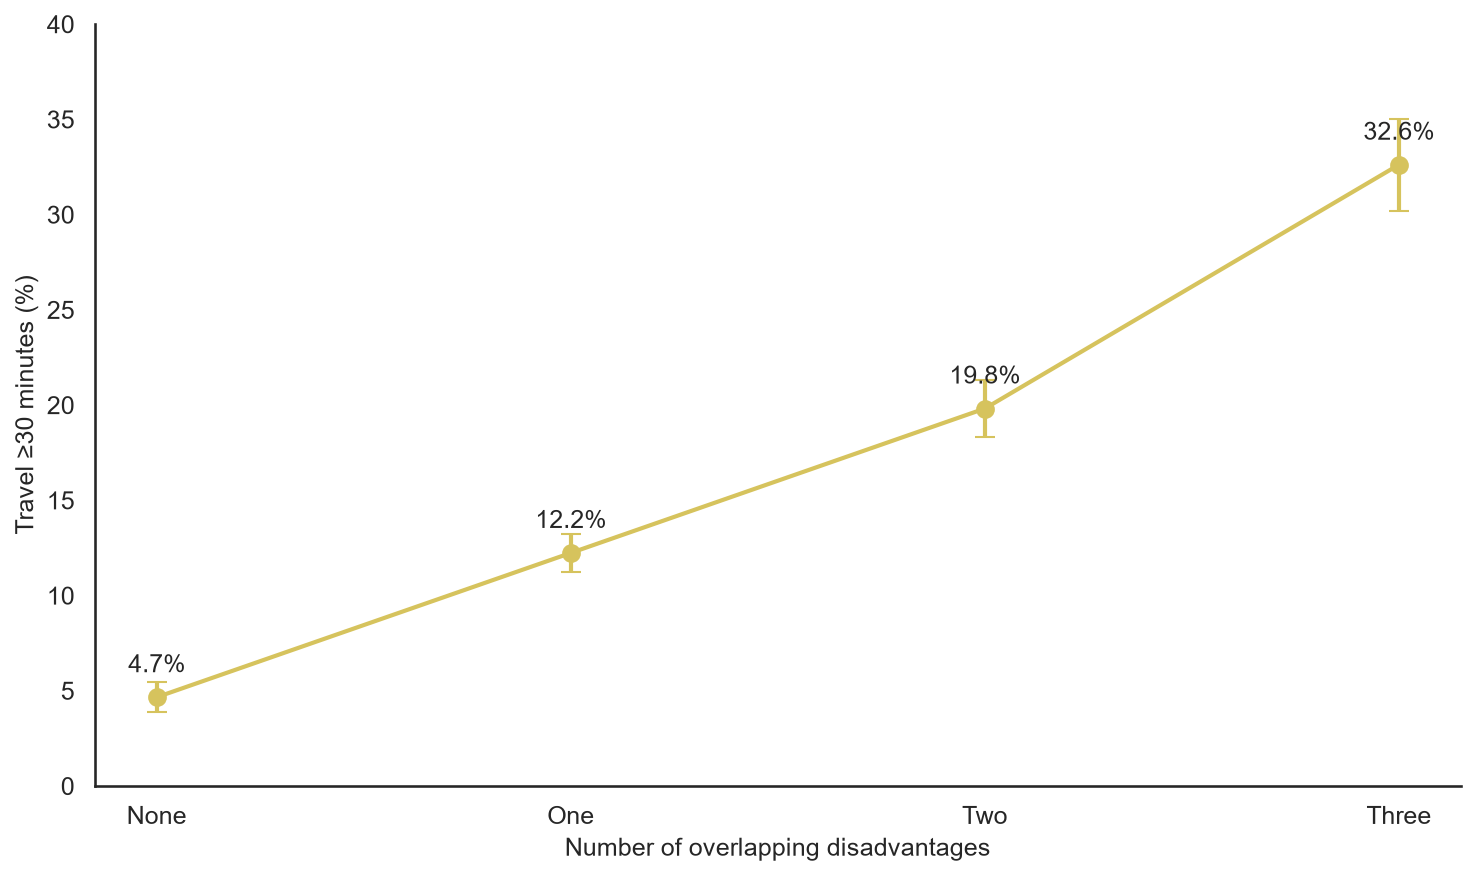

In [8]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Plotting configuration
sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.titlesize": 12,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

sns.set_style("white")

export_png = True
export_pdf = True

out_dir = str(ROOT / "outputs" / "figures")
os.makedirs(out_dir, exist_ok=True)

def safe_name(s: str) -> str:
    return "".join(
        c if (c.isalnum() or c in "-_") else "_"
        for c in s
    ).strip("_")

colors = plt.cm.cividis(np.linspace(0.25, 0.85, 2))

# Figure F11
profiles = pd.read_csv(TABLES / "T19_vulnerability_profiles.csv")

x = profiles["Disadvantages"]
y = profiles["Travel_30min_pct"]
errors = [
    y - profiles["CI_lower_pct"],
    profiles["CI_upper_pct"] - y
]

fig, ax = plt.subplots()

ax.errorbar(
    x, y, yerr=errors,
    fmt="o-", color=colors[1],
    linewidth=2, markersize=8, capsize=5
)

ax.set_xticks([0, 1, 2, 3])
ax.set_xticklabels(["None", "One", "Two", "Three"])
ax.set_xlabel("Number of overlapping disadvantages")
ax.set_ylabel("Travel ≥30 minutes (%)")
ax.set_ylim(0, 40)

sns.despine(ax=ax)

for xi, yi in zip(x, y):
    ax.annotate(
        f"{yi:.1f}%",
        (xi, yi),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center"
    )

plt.tight_layout()

filename = safe_name("F11_vulnerability_gradient")

if export_png:
    fig.savefig(f"{out_dir}/{filename}.png", bbox_inches="tight")

if export_pdf:
    fig.savefig(f"{out_dir}/{filename}.pdf", bbox_inches="tight")

plt.show()

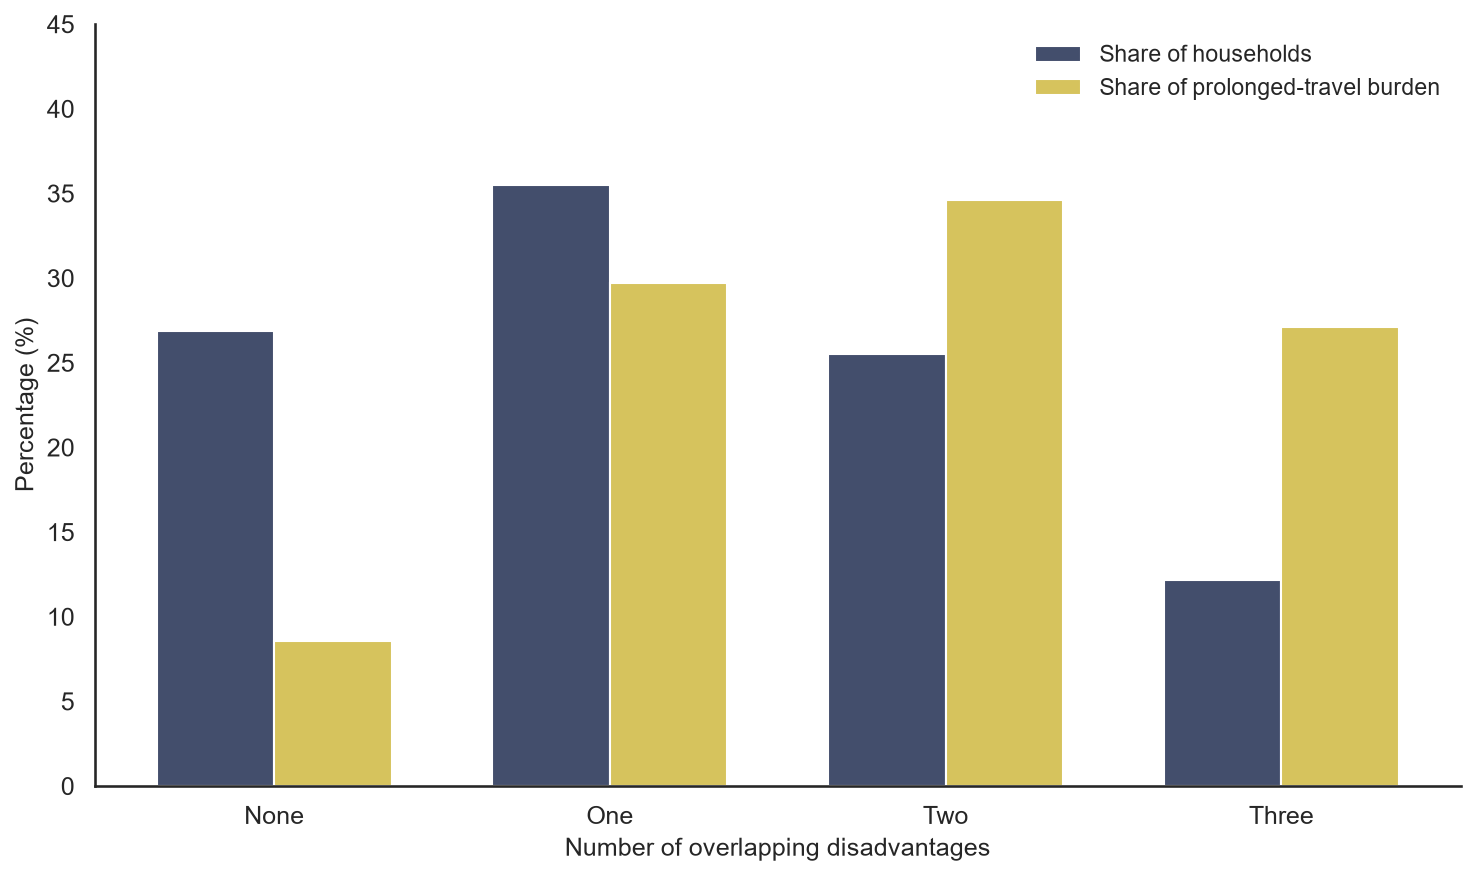

In [9]:
burden = pd.read_csv(TABLES / "T20_profile_population_burden.csv")
profiles = pd.read_csv(TABLES / "T19_vulnerability_profiles.csv")

fig, ax = plt.subplots()

x = np.arange(4)
width = 0.35

ax.bar(
    x - width / 2,
    profiles["Household_share_pct"],
    width, label="Share of households",
    color=colors[0]
)

ax.bar(
    x + width / 2,
    burden["Share_of_travel_burden_pct"],
    width, label="Share of prolonged-travel burden",
    color=colors[1]
)

ax.set_xticks(x)
ax.set_xticklabels(["None", "One", "Two", "Three"])
ax.set_xlabel("Number of overlapping disadvantages")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 45)
ax.legend(frameon=False)

sns.despine(ax=ax)
plt.tight_layout()

filename = safe_name("F12_population_disadvantage_profiles")

if export_png:
    fig.savefig(f"{out_dir}/{filename}.png", bbox_inches="tight")

if export_pdf:
    fig.savefig(f"{out_dir}/{filename}.pdf", bbox_inches="tight")

plt.show()